# Дослідницький аналіз: база VOICED

**База:** VOICED Database (VOice ICar fEDerico II), версія 1.0.0
**Посилання:** https://physionet.org/content/voiced/1.0.0/
**Локальні файли:** `data/voice-icar-federico-ii-database-1.0.0`
**Ліцензія:** [Open Data Commons Attribution License v1.0](https://opendatacommons.org/licenses/by/1.0/). Дані відкриті: для навчального проєкту їх можна використовувати, якщо зберегти посилання на авторів.

Стаття, у якій базу описано: Cesari U., De Pietro G., Marciano E., Niri C., Sannino G., Verde L. *A new database of healthy and pathological voices.* Computers & Electrical Engineering, vol. 68, pp. 310–321, 2018. https://doi.org/10.1016/j.compeleceng.2018.04.008

Сигнал міні-проєкту — стале вимовляння голосного «а», зчитане з `.dat`. Мітка бінарна: `healthy` лишається здоровим класом, усі хвороби зливаються в один патологічний клас.


## 1. Опис експерименту

Базу зібрали Ugo Cesari, Giuseppe De Pietro, Elio Marciano, Ciro Niri, Giovanna Sannino та Laura Verde. Клінічну частину робили лікарі-фоніатри, технічну — інженери ICAR-CNR і Університету Неаполя.

**Де.** Огляди, записи голосу й анкети проходили в амбулаторіях фоніатрії та відеоларингоскопії університетської лікарні Federico II (Неаполь) або в медичному кабінеті Institute of High Performance Computing and Networking (ICAR-CNR). Набір тривав з 16 травня 2016 до 15 травня 2017.

**Хто.** Дорослі 18–70 років, які могли пройти всі етапи. Не брали людей молодше 18 і старше 70, з інфекцією верхніх дихальних шляхів або зі складками (гостре запалення), а також із неврологічними розладами. Здоровий голос і патологію голосових складок підтверджували лікарі за протоколом SIFEL Італійського товариства фоніатрії та логопедії.

**Що робили піддослідні.** Після двох-трьох пробних спроб людина тягнула голосний «а» без перерви, зі сталою гучністю, як у звичайній розмові. За задумом протоколу фрагмент мав тривати п'ять секунд.

**Як міряли.** Запис ішов у реальному часі через мобільну систему Vox4Health, встановлену на Samsung Galaxy S4 (Android 5.0.1). Телефон тримали приблизно за 20 см від людини під кутом близько 45°. Кімната була тиха (фон до 30 дБ) і не надто суха (вологість понад 30–40%). Кожен запис додатково відфільтрували, щоб прибрати випадковий шум; параметрів цього фільтра у файлах немає.

Окрім звуку, для кожної людини збережено стать, вік, діагноз, професію, звички (куріння, алкоголь, кава, вода, продукти, пов'язані з рефлюксом) і два опитувальники: Voice Handicap Index (VHI) та Reflux Symptom Index (RSI).

## 2. Які файли є в базі

На кожен запис `voiceNNN` у архіві лежить кілька файлів. У цьому проєкті використовуються три:

| Файл | Що всередині | Навіщо він нам |
| --- | --- | --- |
| `voiceNNN.dat` | Сигнал, цілі відліки | Єдине джерело семплів |
| `voiceNNN.hea` | Заголовок WFDB: частота, число відліків, формат, підсилення | Щоб правильно прочитати `.dat` |
| `voiceNNN-info.txt` | Анкета: діагноз, VHI, RSI, професія, звички | Мітка і опис людини |

Фізичне значення з `.dat` рахується як `(відлік − baseline) / gain`. У папці є ще `voiceNNN.txt` — текстовий друк того самого сигналу. Його не читаємо і з `.dat` не порівнюємо.

`RECORDS` — список усіх ідентифікаторів. Далі код перевіряє, що список збігається з файлами, і зчитує кожен запис через `src/parse_sound.py`.


In [12]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, Markdown, display

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / "src" / "parse_sound.py").exists() else cwd.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from parse_sound import DATA_FOLDER, parse

pd.set_option("display.max_rows", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.unicode_minus": False,
})

CLASS_ORDER = ["healthy", "pathological"]
CLASS_UK = {"healthy": "здорові", "pathological": "патологічні"}
COLORS = {"healthy": "#2a9d8f", "pathological": "#e76f51"}


def as_class(diagnosis: str) -> str:
    """Усі діагнози, крім healthy, — один патологічний клас."""
    text = " ".join(str(diagnosis).lower().split())
    return "healthy" if text == "healthy" else "pathological"


def leading_zeros(samples: np.ndarray) -> int:
    nonzero = np.flatnonzero(samples != 0)
    if len(nonzero) == 0:
        return int(samples.size)
    return int(nonzero[0])


def zero_crossing_rate(samples: np.ndarray, fs: float) -> float:
    """Переходи через нуль на секунду, уже без початкової тиші."""
    active = samples[leading_zeros(samples):]
    signs = np.sign(active)
    signs[signs == 0] = 1
    crossings = np.count_nonzero(signs[1:] != signs[:-1])
    return float(crossings / (active.size / fs))


def estimate_f0(samples: np.ndarray, fs: float) -> float:
    """Груба оцінка основного тону з одного кадру 50 мс (автокореляція)."""
    active = samples[leading_zeros(samples):]
    frame = int(0.05 * fs)
    mid = active.size // 2
    segment = active[mid - frame // 2: mid + frame // 2]
    segment = segment - segment.mean()
    segment = segment * np.hanning(segment.size)
    corr = np.correlate(segment, segment, mode="full")
    corr = corr[corr.size // 2:]
    low, high = int(fs / 400), int(fs / 70)
    lag = low + int(np.argmax(corr[low:high]))
    return float(fs / lag)


def mean_spectrum(samples: np.ndarray, fs: float, frame: int = 2048) -> np.ndarray:
    active = samples[leading_zeros(samples):]
    active = active - active.mean()
    window = np.hanning(frame)
    spectra = [
        np.abs(np.fft.rfft(active[start:start + frame] * window))
        for start in range(0, active.size - frame, frame // 2)
    ]
    return np.mean(spectra, axis=0)

In [13]:
records_list = (DATA_FOLDER / "RECORDS").read_text().split()
used = {
    ".dat, сигнал": len(list(DATA_FOLDER.glob("voice*.dat"))),
    ".hea, заголовок": len(list(DATA_FOLDER.glob("voice*.hea"))),
    "-info.txt, анкета": len(list(DATA_FOLDER.glob("voice*-info.txt"))),
}
total_bytes = sum(path.stat().st_size for path in DATA_FOLDER.iterdir() if path.is_file())

display(pd.Series(used, name="файлів").to_frame())
print(f"Рядків у RECORDS: {len(records_list)}")
print(f"У кожного запису є .dat: {all((DATA_FOLDER / f'{name}.dat').exists() for name in records_list)}")
print(f"Розмір папки: {total_bytes / 1024**2:.1f} МБ")
print("Семпли далі беруться тільки з .dat.")


,файлів
".dat, сигнал",208
".hea, заголовок",208
"-info.txt, анкета",208


Рядків у RECORDS: 208
У кожного запису є .dat: True
Розмір папки: 110.0 МБ
Семпли далі беруться тільки з .dat.


## 3. Усі записи

Кожен сигнал зчитано з `.dat`, поруч — анкета. Колонка «клас» — це мітка міні-проєкту: `healthy` або `pathological`. Другий клас зібрано з усіх хвороб, без поділу на дисфонії та рефлюкс. Оригінальний діагноз лишається в таблиці, щоб було видно, що саме злито.


In [14]:
rows = []
samples = {}
for name in records_list:
    recording = parse(name)
    signal = recording.samples
    header = recording.header
    info = recording.info
    spec = header.signals[0]
    samples[name] = signal
    peak = float(np.max(np.abs(signal)))
    rms = float(np.sqrt(np.mean(signal**2)))
    rows.append({
        "id": name,
        "ID в анкеті": info["record_id"],
        "вік": info["age"],
        "стать": info["gender"],
        "діагноз": info["diagnosis"],
        "клас": as_class(info["diagnosis"]),
        "професія": info["occupation"],
        "VHI": info["vhi_score"],
        "RSI": info["rsi_score"],
        "куріння": info["smoker"],
        "цигарок/день": info["cigarettes_per_day"],
        "алкоголь": info["alcohol_consumption"],
        "вода, л/день": info["water_litres_per_day"],
        "газована вода": info["carbonated_beverages"],
        "томати": info["tomatoes"],
        "кава": info["coffee"],
        "чашок кави/день": info["coffee_cups_per_day"],
        "шоколад": info["chocolate"],
        "м'який сир": info["soft_cheese"],
        "цитрусові": info["citrus_fruits"],
        "fs, Гц": header.sampling_frequency,
        "відліків": header.n_samples,
        "тривалість, с": header.n_samples / header.sampling_frequency,
        "тиша на початку, с": leading_zeros(signal) / header.sampling_frequency,
        "формат, біт": spec.sample_format,
        "одиниці": spec.units,
        "RMS": rms,
        "пік": peak,
        "crest": peak / rms,
        "ZCR, 1/с": zero_crossing_rate(signal, header.sampling_frequency),
        "F0, Гц": estimate_f0(signal, header.sampling_frequency),
        "вік у .hea": header.age,
        "стать у .hea": header.sex,
        "діагноз у .hea": header.diagnoses,
    })

meta = pd.DataFrame(rows).set_index("id")
meta["клас"] = pd.Categorical(meta["клас"], categories=CLASS_ORDER, ordered=True)
meta

,ID в анкеті,вік,стать,діагноз,клас,професія,VHI,RSI,куріння,цигарок/день,алкоголь,"вода, л/день",газована вода,томати,кава,чашок кави/день,шоколад,м'який сир,цитрусові,"fs, Гц",відліків,"тривалість, с","тиша на початку, с","формат, біт",одиниці,RMS,пік,crest,"ZCR, 1/с","F0, Гц",вік у .hea,стать у .hea,діагноз у .hea
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
voice001,voice001,32,m,hyperkinetic dysphonia,pathological,Researcher,15,5,no,NaN,casual drinker,1.50,almost never,sometimes,almost always,4.0,almost never,sometimes,sometimes,8000.0,38080,4.76,0.113500,32,NU,0.130236,0.590118,4.531146,1911.976757,111.111111,32,M,hyperkinetic dysphonia
voice002,voice002,55,m,healthy,healthy,Employee,17,12,casual smoker,2.0,habitual drinker,0.50,almost always,sometimes,sometimes,3.0,sometimes,almost always,almost always,8000.0,38080,4.76,0.115625,32,NU,0.291000,0.906860,3.116364,1797.658458,129.032258,55,M,healthy
voice003,voice003,34,m,hyperkinetic dysphonia (nodule),pathological,Researcher,42,26,no,NaN,casual drinker,1.50,sometimes,sometimes,almost always,NaN,sometimes,almost always,almost never,8000.0,38080,4.76,0.115750,32,NU,0.259768,0.925568,3.563052,1724.282715,142.857143,34,M,hyperkinetic dysphonia
voice004,voice004,28,f,hypokinetic dysphonia,pathological,Researcher,20,9,casual smoker,NaN,casual drinker,1.00,almost never,sometimes,always,3.0,sometimes,almost always,sometimes,8000.0,38080,4.76,0.116000,32,NU,0.051169,0.185791,3.630935,1341.731266,190.476190,28,F,hypokinetic dysphonia
voice005,voice005,54,f,hypokinetic dysphonia,pathological,Researcher,39,23,no,NaN,casual drinker,1.50,never,sometimes,never,NaN,sometimes,sometimes,almost always,8000.0,38080,4.76,0.116375,32,NU,0.185829,0.586456,3.155896,1971.735444,166.666667,54,F,hypokinetic dysphonia
voice006,voice005,54,f,hypokinetic dysphonia,pathological,Researcher,39,25,no,NaN,casual drinker,1.50,never,sometimes,never,NaN,sometimes,sometimes,almost always,8000.0,38080,4.76,0.116000,32,NU,0.196327,0.912170,4.646170,1562.015504,114.285714,41,M,hyperkinetic dysphonia
voice007,voice007,41,m,hyperkinetic dysphonia (nodule),pathological,Researcher,24,28,yes,18.0,habitual drinker,1.00,almost never,almost always,always,3.0,sometimes,sometimes,almost always,8000.0,38080,4.76,0.115875,32,NU,0.125501,0.544312,4.337096,1333.728097,102.564103,41,M,hyperkinetic dysphonia
voice008,voice008,51,f,reflux laryngitis,pathological,Researcher,19,15,no,NaN,casual drinker,1.00,almost never,almost always,always,2.0,almost always,sometimes,almost always,8000.0,38080,4.76,0.119250,32,NU,0.176653,0.578339,3.273870,1501.050477,190.476190,51,F,reflux laryngitis
voice009,voice009,53,f,hyperkinetic dysphonia (nodule),pathological,Researcher,10,15,yes,20.0,habitual drinker,1.50,almost never,almost never,always,3.0,almost always,sometimes,almost always,8000.0,38080,4.76,0.119125,32,NU,0.110047,0.421539,3.830552,1153.015326,163.265306,53,F,hyperkinetic dysphonia


## 4. Характеристики сигналу

У заголовку WFDB один канал. Частота дискретизації записана в першому рядку `.hea`, розрядність — у полі формату сигналу (32). Окреме поле ADC resolution у цих файлах дорівнює 0: для WFDB це означає «не вказано», а не «0 біт». Одиниці стоять як `NU` (not specified): після перерахунку через gain сигнал лежить приблизно в діапазоні від −1 до 1, це нормована амплітуда, не мілівольти.

Протокол обіцяє п'ять секунд. У файлах фрагмент трохи коротший, і кожен запис починається з короткої нульової ділянки — близько десятих секунди. Її варто пам'ятати, якщо далі різати сигнал на вікна: це не голос.

In [15]:
fs = meta["fs, Гц"]
print("Частота дискретизації, унікальні значення:", sorted(fs.unique().tolist()))
print("Каналів у кожному .hea: 1")
print("Формат відліку, біт:", sorted(meta["формат, біт"].unique().tolist()))
print("Одиниці після перерахунку:", sorted(meta["одиниці"].unique().tolist()))
print(f"Частота Найквіста: {fs.iloc[0] / 2:.0f} Гц")

characteristics = pd.DataFrame({
    "тривалість, с": meta["тривалість, с"].describe(),
    "відліків": meta["відліків"].describe(),
    "тиша на початку, с": meta["тиша на початку, с"].describe(),
    "RMS": meta["RMS"].describe(),
    "пік": meta["пік"].describe(),
})
display(characteristics)

print("Скільки записів мають кожну довжину:")
display(meta["відліків"].value_counts().sort_index().rename("записів").to_frame())

Частота дискретизації, унікальні значення: [8000.0]
Каналів у кожному .hea: 1
Формат відліку, біт: [32]
Одиниці після перерахунку: ['NU']
Частота Найквіста: 4000 Гц


,"тривалість, с",відліків,"тиша на початку, с",RMS,пік
count,208.000000,208.000000,208.000000,208.000000,208.000000
mean,4.756731,38053.846154,0.115176,0.196734,0.742808
std,0.016591,132.725482,0.002403,0.070158,0.208203
min,4.720000,37760.000000,0.108875,0.038771,0.135406
25%,4.760000,38080.000000,0.113594,0.150142,0.609543
50%,4.760000,38080.000000,0.115125,0.195999,0.782242
75%,4.760000,38080.000000,0.116625,0.252971,0.919281
max,4.840000,38720.000000,0.128750,0.348098,1.000000


Скільки записів мають кожну довжину:


,записів
відліків,
37760,26
38080,174
38400,7
38720,1


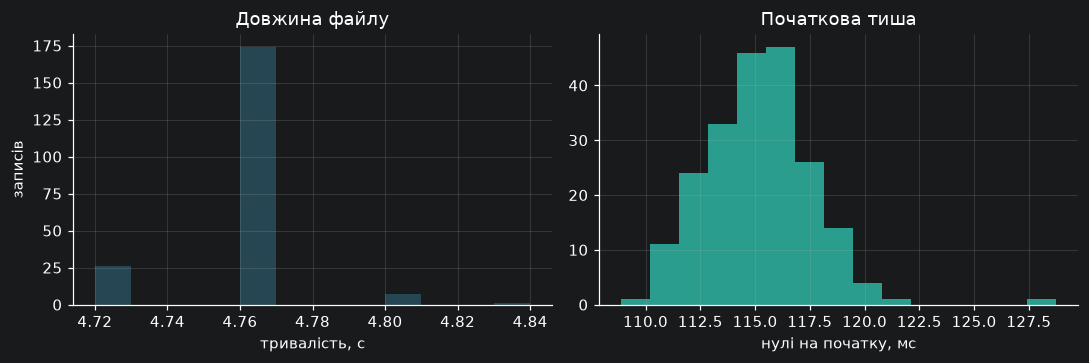

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(meta["тривалість, с"], bins=12, color="#264653")
axes[0].set_xlabel("тривалість, с")
axes[0].set_ylabel("записів")
axes[0].set_title("Довжина файлу")
axes[1].hist(meta["тиша на початку, с"] * 1000, bins=15, color="#2a9d8f")
axes[1].set_xlabel("нулі на початку, мс")
axes[1].set_title("Початкова тиша")
fig.tight_layout()

In [17]:
example_id = "voice001"
print((DATA_FOLDER / f"{example_id}.hea").read_text())
print((DATA_FOLDER / f"{example_id}-info.txt").read_text())

voice001 1 8000 38080
voice001.dat 32 4079702243.3775(-260023747)/NU 0 0 -260023747 14973 0 voice
#<age>: 32  <sex>: M <diagnoses>: hyperkinetic dysphonia <medications>: none

ID	voice001
	
Age:	32
Gender:	m
Diagnosis:	hyperkinetic dysphonia
Occupation status:	Researcher
	
	
Voice Handicap Index (VHI) Score:	15
Reflux Symptom Index (RSI) Score:	5
	
	
Smoker:	no
Number of cigarettes smoked per day:	NU
	
Alcohol consumption:	casual drinker
Number of glasses containing alcoholic beverage drinked in a day	NU
Amount of water's litres drink every day:	1,5
	
Eating habits:	
Carbonated beverages:	almost never
Amount of glasses drinked in a day	NU
Tomatoes:	sometimes
Coffee:	almost always
Number of cups of coffee drinked in a day	4
Chocolate:	almost never
Gramme of chocolate eaten in  a day	NU
Soft cheese:	sometimes
Gramme of soft cheese eaten in a day	NU
Citrus fruits:	sometimes
Number of citrus fruits eaten in a day	NU



## 5. Як виглядає сигнал

Нижче по одному запису на кожну комбінацію класу і статі: здоровий і патологічний, жінка і чоловік. Патологічні приклади підписані класом моделі, а не окремою хворобою. Ліворуч — увесь файл із `.dat`, праворуч — 30 мс із середини, щоб було видно період основного тону. Масштаб амплітуди спільний.

Плеєр програє той самий масив, який прочитано з `.dat`, разом із короткою тишею на початку.


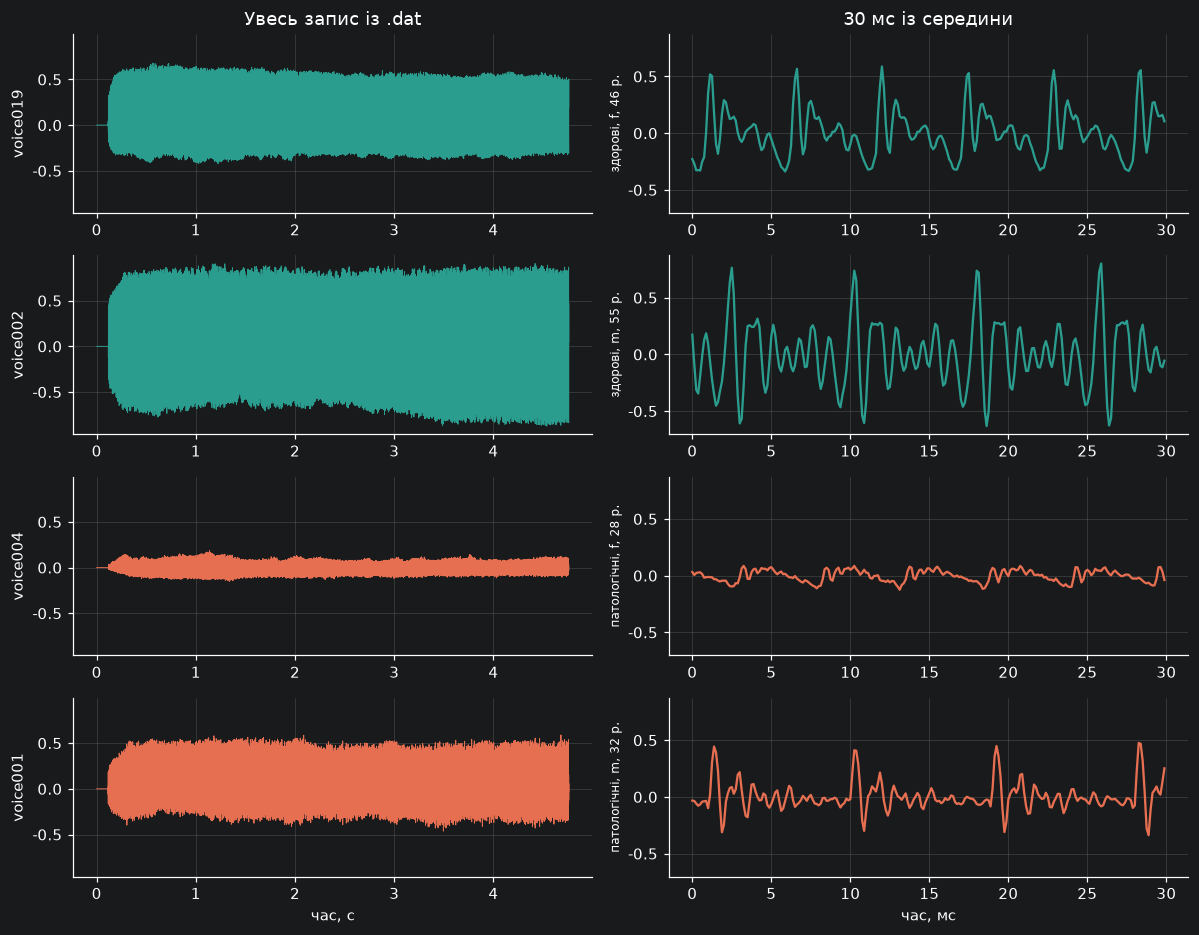

In [18]:
example_ids = []
for label in CLASS_ORDER:
    for sex in ("f", "m"):
        match = meta.index[(meta["клас"] == label) & (meta["стать"] == sex)]
        example_ids.append(match[0])

n = len(example_ids)
fig, axes = plt.subplots(n, 2, figsize=(11, 2.15 * n), sharey="col")
for row, name in enumerate(example_ids):
    signal = samples[name]
    fs = meta.loc[name, "fs, Гц"]
    time = np.arange(signal.size) / fs
    label = str(meta.loc[name, "клас"])
    color = COLORS[label]
    axes[row, 0].plot(time, signal, color=color, linewidth=0.6)
    axes[row, 0].set_ylabel(name)
    mid = signal.size // 2
    zoom = signal[mid: mid + int(0.03 * fs)]
    axes[row, 1].plot(np.arange(zoom.size) / fs * 1000, zoom, color=color)
    caption = f"{CLASS_UK[label]}, {meta.loc[name, 'стать']}, {meta.loc[name, 'вік']} р."
    axes[row, 1].set_ylabel(caption, fontsize=8)
axes[0, 0].set_title("Увесь запис із .dat")
axes[0, 1].set_title("30 мс із середини")
axes[-1, 0].set_xlabel("час, с")
axes[-1, 1].set_xlabel("час, мс")
fig.tight_layout()


In [19]:
for name in example_ids:
    label = CLASS_UK[str(meta.loc[name, "клас"])]
    display(Markdown(f"**{name}** — {label}. В анкеті: {meta.loc[name, 'діагноз']}"))
    display(Audio(samples[name], rate=int(meta.loc[name, "fs, Гц"])))


**voice019** — здорові. В анкеті: healthy

**voice002** — здорові. В анкеті: healthy

**voice004** — патологічні. В анкеті: hypokinetic dysphonia

**voice001** — патологічні. В анкеті: hyperkinetic dysphonia

## 6. Амплітуда, спектр і основний тон

Порівняння нижче — між двома класами, які підуть у модель. Окремі хвороби тут не розведені.

RMS і crest factor (пік / RMS) описують, наскільки сигнал «гострий». Нульові переходи (ZCR) ростуть і від висоти тону, і від шумової складової, тому це не частота основного тону. Окремо F0 оцінено автокореляцією одного кадру 50 мс у діапазоні 70–400 Гц: для жіночих голосів оцінка вища, ніж для чоловічих, але на окремих файлах метод може зіскочити на октаву. Це орієнтир для EDA, не клінічний вимір.

Середній спектр пораховано по семплах із `.dat`, вікнами Хеннінга по 2048 відліків (256 мс, крок 128 мс), уже після відкидання початкових нулів. Смуга зверху обрізана частотою Найквіста, 4 кГц.


In [20]:
feature_cols = ["RMS", "пік", "crest", "ZCR, 1/с", "F0, Гц"]
by_class = meta.groupby("клас", observed=True)[feature_cols].agg(["median", "mean", "std"])
by_class.index = by_class.index.map(CLASS_UK)
display(by_class.round(2))

by_sex = meta.groupby("стать")[["F0, Гц", "ZCR, 1/с"]].agg(["median", "mean"])
display(by_sex.round(1))


RMS                пік              crest             ZCR, 1/с                   F0, Гц               
            median  mean   std median  mean   std median  mean   std   median     mean     std  median    mean    std
клас                                                                                                                 
здорові       0.20  0.21  0.07   0.72  0.72  0.19   3.45  3.57  0.60  1607.20  1604.82  320.02  195.12  197.06  48.85
патологічні   0.19  0.19  0.07   0.84  0.75  0.21   3.83  4.23  1.93  1574.03  1576.68  390.11  181.82  182.39  51.70

F0, Гц        ZCR, 1/с        
      median   mean   median    mean
стать                               
f      210.5  208.9   1602.3  1600.5
m      144.2  143.9   1565.8  1554.0

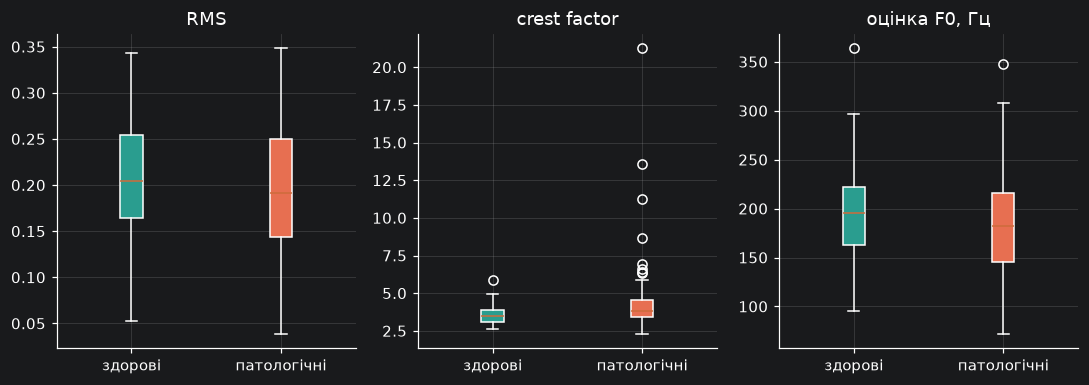

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
plot_cols = ["RMS", "crest", "F0, Гц"]
titles = ["RMS", "crest factor", "оцінка F0, Гц"]
for ax, column, title in zip(axes, plot_cols, titles):
    data = [meta.loc[meta["клас"] == label, column] for label in CLASS_ORDER]
    box = ax.boxplot(data, tick_labels=[CLASS_UK[label] for label in CLASS_ORDER], patch_artist=True)
    for patch, label in zip(box["boxes"], CLASS_ORDER):
        patch.set_facecolor(COLORS[label])
    ax.set_title(title)
fig.tight_layout()


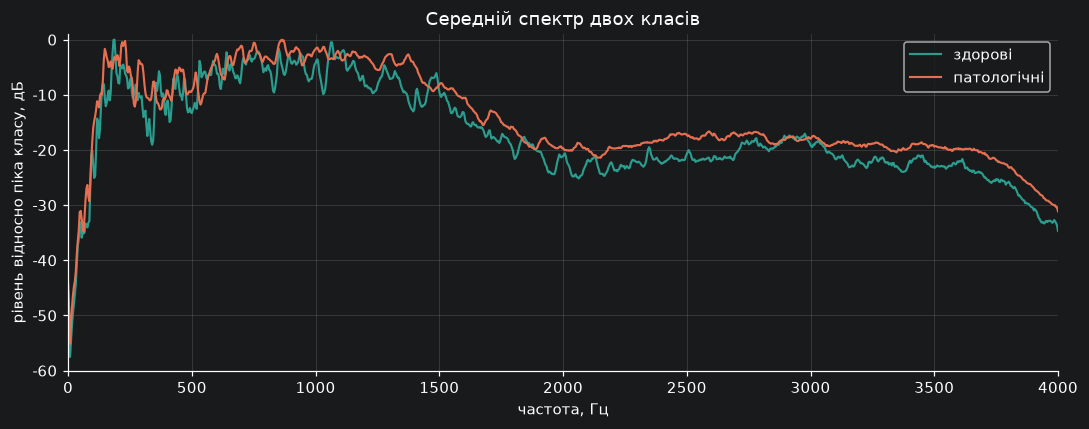

In [22]:
frame = 2048
fs = float(meta["fs, Гц"].iloc[0])
freqs = np.fft.rfftfreq(frame, d=1 / fs)
fig, ax = plt.subplots(figsize=(10, 4))
for label in CLASS_ORDER:
    names = meta.index[meta["клас"] == label]
    spectra = np.vstack([mean_spectrum(samples[name], fs, frame) for name in names])
    mean = spectra.mean(axis=0)
    decibels = 20 * np.log10(mean / mean.max())
    ax.plot(freqs, decibels, color=COLORS[label], label=CLASS_UK[label], linewidth=1.4)
ax.set_xlim(0, fs / 2)
ax.set_ylim(-60, 1)
ax.set_xlabel("частота, Гц")
ax.set_ylabel("рівень відносно піка класу, дБ")
ax.set_title("Середній спектр двох класів")
ax.legend()
fig.tight_layout()


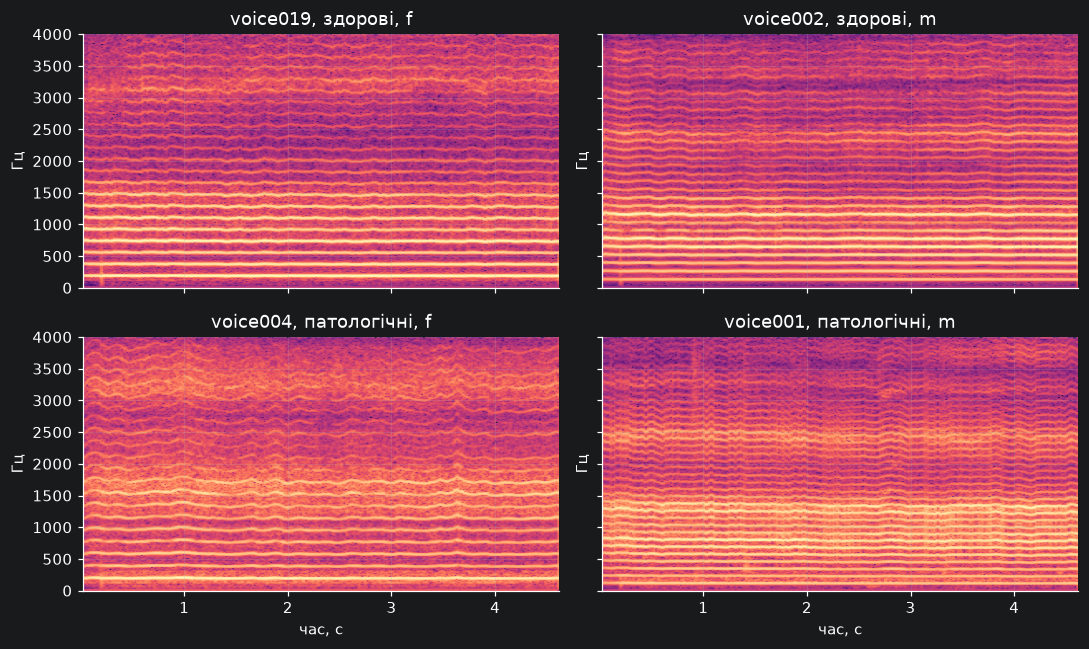

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), example_ids):
    signal = samples[name]
    fs = meta.loc[name, "fs, Гц"]
    active = signal[leading_zeros(signal):]
    label = CLASS_UK[str(meta.loc[name, "клас"])]
    ax.specgram(active, NFFT=512, Fs=fs, noverlap=384, cmap="magma")
    ax.set_ylim(0, fs / 2)
    ax.set_title(f"{name}, {label}, {meta.loc[name, 'стать']}")
    ax.set_ylabel("Гц")
axes[1, 0].set_xlabel("час, с")
axes[1, 1].set_xlabel("час, с")
fig.tight_layout()


## 7. Хто в базі

На сайті PhysioNet написано 58 здорових і 150 патологічних голосів. У файлах цієї копії мітка `healthy` стоїть у 57 анкетах, решта записів має якийсь патологічний діагноз. Для моделі це два класи, а не список хвороб.

Жінок більше, ніж чоловіків. Вік покриває весь заявлений діапазон 18–70 років. Патологічний клас більший за здоровий, тож вибірка незбалансована.


In [24]:
n_healthy = int((meta["клас"] == "healthy").sum())
print(f"Записів: {len(meta)}")
print(f"Здорові: {n_healthy}")
print(f"Патологічні (усі хвороби разом): {len(meta) - n_healthy}")
print("Стать:", meta["стать"].value_counts().to_dict())
print(f"Вік: {meta['вік'].min()}–{meta['вік'].max()}, середнє {meta['вік'].mean():.1f}, медіана {meta['вік'].median():.0f}")

counts = meta["клас"].value_counts().reindex(CLASS_ORDER)
counts.index = counts.index.map(CLASS_UK)
display(counts.rename("записів").to_frame())
display(pd.crosstab(meta["стать"], meta["клас"].map(CLASS_UK), margins=True))


Записів: 208
Здорові: 57
Патологічні (усі хвороби разом): 151
Стать: {'f': 136, 'm': 72}
Вік: 18–70, середнє 44.1, медіана 45


,записів
клас,
здорові,57
патологічні,151


клас,здорові,патологічні,All
стать,,,
f,36,100,136
m,21,51,72
All,57,151,208


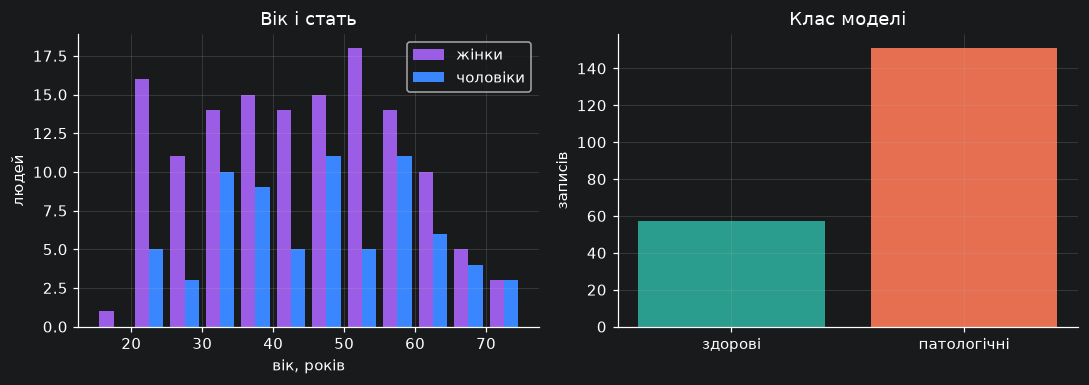

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(
    [meta.loc[meta["стать"] == sex, "вік"] for sex in ("f", "m")],
    bins=np.arange(15, 76, 5),
    label=["жінки", "чоловіки"],
    color=["#9b5de5", "#3a86ff"],
)
axes[0].set_xlabel("вік, років")
axes[0].set_ylabel("людей")
axes[0].legend()
axes[0].set_title("Вік і стать")

counts = meta["клас"].value_counts().reindex(CLASS_ORDER)
axes[1].bar(
    [CLASS_UK[label] for label in CLASS_ORDER],
    counts.to_numpy(),
    color=[COLORS[label] for label in CLASS_ORDER],
)
axes[1].set_ylabel("записів")
axes[1].set_title("Клас моделі")
fig.tight_layout()


У патологічний клас входять усі діагнози, крім `healthy`. Нижче їхній перелік із анкети: для навчання це один клас. Частина підписів дублюється через регістр і пробіли (`Nodule` / `nodule`), тому ділити вибірку за цими рядками не варто.


In [26]:
pathological = meta.loc[meta["клас"] == "pathological", "діагноз"]
print(f"У патологічному класі {len(pathological)} записів і {pathological.nunique()} різних підписів.")
display(pathological.value_counts().rename("записів").to_frame())


У патологічному класі 151 записів і 26 різних підписів.


,записів
діагноз,
hyperkinetic dysphonia,43
reflux laryngitis,38
hypokinetic dysphonia,22
hyperkinetic dysphonia (Prolapse),9
hypokinetic dysphonia (glottic insufficiency),6
hyperkinetic dysphonia (Polyps),5
hypokinetic dysphonia (Vocal fold paralysis),4
hyperkinetic dysphonia (nodule),3
hyperkinetic dysphonia (Reinke's edema),3


## 8. Анкети: VHI, RSI, професія, звички

VHI — наскільки сама людина відчуває проблему з голосом (0–120). RSI — симптоми ларингофарингеального рефлюксу; у літературі поріг 13 часто використовують як межу «багато рефлюксних скарг», це не діагноз із цієї бази. Професія і звички зібрані тому, що голос залежить і від навантаження (співаки, викладачі), і від куріння та рефлюксу. У частині анкет професія порожня (`NU`).

Мітки куріння в файлах написані по-різному: `no` і `No`. Нижче для підрахунку регістр зведено.

VHI                        RSI                   
            median       mean min  max median       mean min max
клас                                                            
здорові        3.0  11.701754   0   86   11.0  10.421053   0  26
патологічні   24.0  28.430464   0  106   12.0  12.582781   0  41

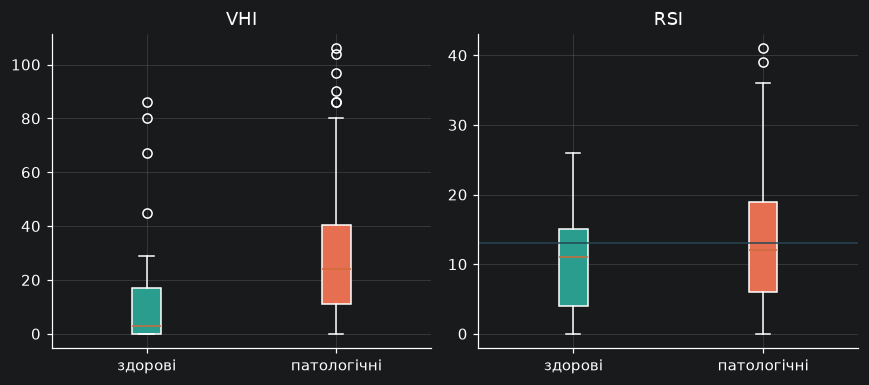

In [27]:
score_summary = meta.groupby("клас", observed=True)[["VHI", "RSI"]].agg(["median", "mean", "min", "max"])
score_summary.index = score_summary.index.map(CLASS_UK)
display(score_summary)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, column in zip(axes, ("VHI", "RSI")):
    data = [meta.loc[meta["клас"] == label, column] for label in CLASS_ORDER]
    box = ax.boxplot(data, tick_labels=[CLASS_UK[label] for label in CLASS_ORDER], patch_artist=True)
    for patch, label in zip(box["boxes"], CLASS_ORDER):
        patch.set_facecolor(COLORS[label])
    ax.set_title(column)
axes[1].axhline(13, color="#264653", linewidth=1)
fig.tight_layout()


In [28]:
occupation = meta["професія"].fillna("не вказано").value_counts()
display(occupation.rename("людей").to_frame())

smoker = meta["куріння"].str.strip().str.lower().replace({"casual smoker": "casual"})
print("Куріння, після зведення регістру:")
display(pd.crosstab(smoker, meta["клас"].map(CLASS_UK), margins=True))
print("Алкоголь:")
display(pd.crosstab(meta["алкоголь"], meta["клас"].map(CLASS_UK), margins=True))
print(f"Вода, л/день: медіана {meta['вода, л/день'].median():.1f}, від {meta['вода, л/день'].min()} до {meta['вода, л/день'].max()}")


,людей
професія,
Researcher,43
не вказано,41
Employee,25
Housewife,23
Student,16
Technical operator,14
Singer,10
Pensioner,6
Doctor,5


Куріння, після зведення регістру:


клас,здорові,патологічні,All
куріння,,,
casual,4,7,11
no,47,107,154
yes,6,37,43
All,57,151,208


Алкоголь:


клас,здорові,патологічні,All
алкоголь,,,
casual drinker,28,73,101
habitual drinker,5,18,23
nondrinker,24,60,84
All,57,151,208


Вода, л/день: медіана 1.5, від 0.25 до 2.5


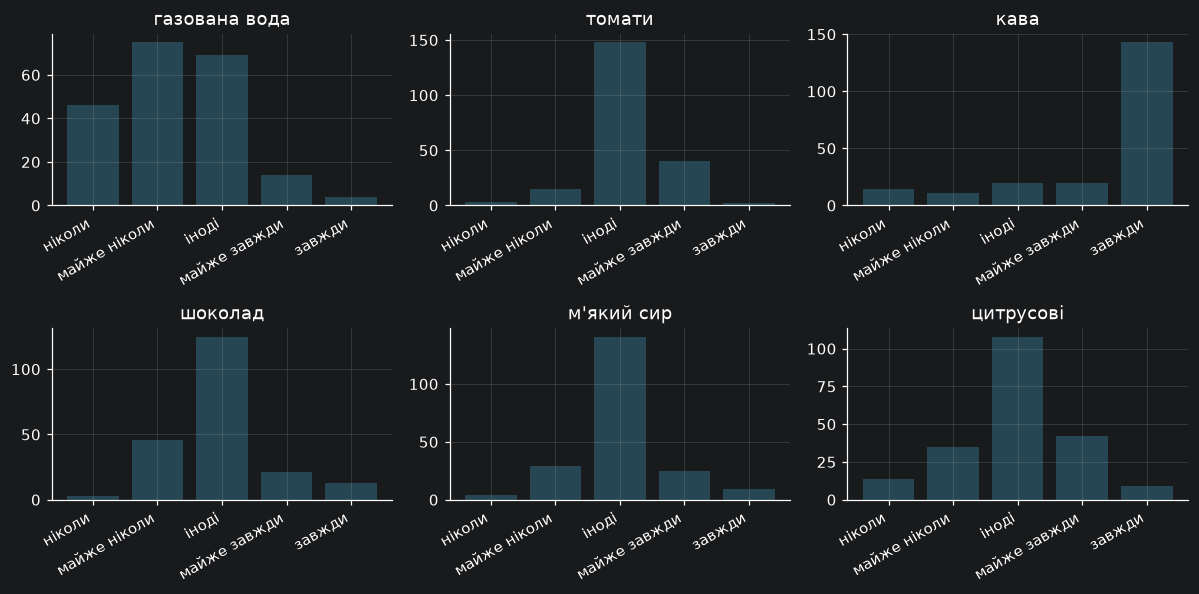

In [29]:
habit_cols = ["газована вода", "томати", "кава", "шоколад", "м'який сир", "цитрусові"]
order = ["never", "almost never", "sometimes", "almost always", "always"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, column in zip(axes.ravel(), habit_cols):
    counts = meta[column].value_counts().reindex(order).fillna(0)
    ax.bar(range(len(order)), counts.to_numpy(), color="#264653")
    ax.set_xticks(range(len(order)), ["ніколи", "майже ніколи", "іноді", "майже завжди", "завжди"], rotation=30, ha="right")
    ax.set_title(column)
fig.tight_layout()

## 9. Де файли однієї людини не збігаються

Рядок таблиці — це ім'я файлу (`voiceNNN`), бо поле `ID` всередині анкети йому не завжди дорівнює. Для бінарної мітки звіряємо лише healthy / не healthy: уточнення хвороби в дужках на клас не впливають.


In [30]:
id_mismatch = meta.loc[
    meta.index != meta["ID в анкеті"],
    ["ID в анкеті", "вік", "стать", "клас", "діагноз", "вік у .hea", "стать у .hea", "діагноз у .hea"],
]
print(f"ID в анкеті не збігається з іменем файлу: {len(id_mismatch)}")
display(id_mismatch)

same_person = ["вік", "стать", "клас", "вік у .hea", "стать у .hea", "діагноз", "діагноз у .hea", "VHI", "RSI"]
print("voice006-info.txt майже повторює voice005-info.txt (інший лише RSI), а заголовок voice006 описує іншу людину.")
display(meta.loc[["voice005", "voice006"], same_person])
print("voice054-info.txt майже повторює voice055-info.txt, у заголовку voice054 інший вік.")
display(meta.loc[["voice054", "voice055"], same_person])

header_class = meta["діагноз у .hea"].map(as_class)
class_mismatch = meta.loc[meta["клас"].astype(str) != header_class, ["клас", "діагноз", "діагноз у .hea"]]
print(f"Бінарний клас анкети і .hea різний: {len(class_mismatch)}")
display(class_mismatch)


ID в анкеті не збігається з іменем файлу: 2


,ID в анкеті,вік,стать,клас,діагноз,вік у .hea,стать у .hea,діагноз у .hea
id,,,,,,,,
voice006,voice005,54,f,pathological,hypokinetic dysphonia,41,M,hyperkinetic dysphonia
voice054,voice055,46,m,pathological,hyperkinetic dysphonia,60,M,hyperkinetic dysphonia


voice006-info.txt майже повторює voice005-info.txt (інший лише RSI), а заголовок voice006 описує іншу людину.


,вік,стать,клас,вік у .hea,стать у .hea,діагноз,діагноз у .hea,VHI,RSI
id,,,,,,,,,
voice005,54,f,pathological,54,F,hypokinetic dysphonia,hypokinetic dysphonia,39,23
voice006,54,f,pathological,41,M,hypokinetic dysphonia,hyperkinetic dysphonia,39,25


voice054-info.txt майже повторює voice055-info.txt, у заголовку voice054 інший вік.


,вік,стать,клас,вік у .hea,стать у .hea,діагноз,діагноз у .hea,VHI,RSI
id,,,,,,,,,
voice054,46,m,pathological,60,M,hyperkinetic dysphonia,hyperkinetic dysphonia,15,19
voice055,46,m,pathological,46,M,hyperkinetic dysphonia,hyperkinetic dysphonia,15,10


Бінарний клас анкети і .hea різний: 0


,клас,діагноз,діагноз у .hea
id,,,


## 10. Висновки

Записів достатньо для навчальної задачі: один канал, одна частота, майже одна довжина, одна голосова задача. Семпли беруться з `.dat`. Мітка — два класи: здоровий і один спільний патологічний, куди злито всі хвороби з анкети.

Що варто врахувати далі:

- Патологічних записів приблизно в 2.6 раза більше, ніж здорових. Точність без розбивки по класах буде оманливою.
- Перед ознаками або нейромережею початкові нулі краще відрізати. Інакше модель бачить одну й ту саму паузу в кожному файлі.
- Смуга обмежена 4 кГц. Для голосного «а» основний тон і нижні гармоніки в цю смугу потрапляють.
- Дрібні підписи хвороб у модель не йдуть. Вони лише показують, з чого зібрано патологічний клас.
- У `voice006-info.txt` і `voice054-info.txt` поле ID вказує на сусідній запис, а текст анкети майже збігається з `voice005` і `voice055`. На бінарний клас це не перекидає: обидва записи лишаються патологічними і в анкеті, і в `.hea`. Вік і стать у цих двох анкетах ненадійні.
- VHI у патологічному класі вищий. Для класифікації за звуком анкету не можна давати моделі на вхід: вона вже містить самооцінку хвороби.
